# Week 8 — Model Evaluation
## Comparing classification models fairly

In this notebook, we will practise the evaluation ideas from Lecture 8:

- Why performance on training data is not enough
- The roles of training, validation and test sets
- Confusion matrices, accuracy, precision, recall and F1
- Cross-validation for fair model comparison
- Avoiding data leakage with a `Pipeline`

We use a **simulated student-support dataset**. It is artificial and is only for practising machine-learning methods; it does not describe real students and should not be used to make decisions about people.

## 1. Set up the example

We will predict whether a student is likely to need additional support, using a few simulated indicators. The target has two classes: `0 = no additional support indicated`, `1 = additional support indicated`.

The data are generated for teaching purposes, so the patterns are deliberately simplified.

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay, confusion_matrix,
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report
)

RANDOM_STATE = 42

feature_names = [
    "attendance", "study_time", "engagement",
    "assessment_score", "help_seeking"
]

df = pd.read_csv("../data/week8_evaluation_synt_data.csv")
X = df[feature_names]
y = df["needs_support"]

display(X.head())
print("Class counts:")
print(y.value_counts().sort_index().rename(index={0: "0 = no", 1: "1 = yes"}))


,attendance,study_time,engagement,assessment_score,help_seeking
0,-1.041490,-0.925348,-0.501729,-1.003260,-1.105530
1,-0.119755,1.354278,-1.064756,2.632053,1.250987
2,1.417070,1.143574,-1.014636,-0.260747,1.557958
3,-1.403978,0.181318,-1.833510,-1.254397,-2.164292
4,2.042914,1.249530,1.235293,1.305766,0.178525


Class counts:
needs_support
0 = no     714
1 = yes    286
Name: count, dtype: int64


Why is it important to know how common each class is before choosing an evaluation metric?

In [11]:
# Inspect the class balance as proportions.
y.value_counts(normalize=True).sort_index()

needs_support
0    0.714
1    0.286
Name: proportion, dtype: float64

## 2. Split the data before fitting a model

The **training set** is used to fit model parameters. The **validation set** (or cross-validation) helps compare models and tune settings. The **test set** is held back for a final, independent estimate.

Here we make a 60% training, 20% validation and 20% test split. `stratify=y` helps preserve the class proportions in each split.

In [12]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, random_state=RANDOM_STATE, stratify=y
)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=y_temp
)

print(f"Train:      {len(X_train):4d} rows ({len(X_train)/len(X):.0%})")
print(f"Validation: {len(X_valid):4d} rows ({len(X_valid)/len(X):.0%})")
print(f"Test:       {len(X_test):4d} rows ({len(X_test)/len(X):.0%})")

Train:       600 rows (60%)
Validation:  200 rows (20%)
Test:        200 rows (20%)


## 3. Compare a few classifiers on validation data

We will compare Logistic Regression, K-Nearest Neighbours (KNN), and a Decision Tree. Scaling matters for Logistic Regression and KNN, so those models use a pipeline. The scaler is fitted only on the training data.

We use the validation set for model comparison here. We will not use the test set to choose the winner.

In [13]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ]),
    "KNN (k=15)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=15))
    ]),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5, random_state=RANDOM_STATE
    )
}

validation_rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_valid)
    validation_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_valid, pred),
        "Precision": precision_score(y_valid, pred, zero_division=0),
        "Recall": recall_score(y_valid, pred, zero_division=0),
        "F1": f1_score(y_valid, pred, zero_division=0)
    })

validation_results = pd.DataFrame(validation_rows).set_index("Model").sort_values("F1", ascending=False)
validation_results.round(3)

,Accuracy,Precision,Recall,F1
Model,,,,
KNN (k=15),0.915,0.976,0.719,0.828
Decision Tree,0.895,0.929,0.684,0.788
Logistic Regression,0.760,0.696,0.281,0.400


### Which metric should we use?

- **Accuracy:** proportion of all predictions that are correct.
- **Precision:** among cases predicted positive, the proportion that are truly positive.
- **Recall:** among truly positive cases, the proportion identified by the model.
- **F1:** combines precision and recall into one score.

The best metric depends on the consequences of false positives and false negatives. In a support-screening example, missing someone who needs support may be costly, but incorrectly flagging someone also has consequences.

## 4. Read a confusion matrix

The confusion matrix compares predicted labels with actual labels. In scikit-learn, rows are the actual classes and columns are the predicted classes.

For this example, class `1` is the positive class:
- **True Positive (TP):** predicted 1, actual 1
- **True Negative (TN):** predicted 0, actual 0
- **False Positive (FP):** predicted 1, actual 0
- **False Negative (FN):** predicted 0, actual 1

Selected using validation F1: KNN (k=15)
Confusion matrix (actual rows, predicted columns):
[[142   1]
 [ 16  41]]


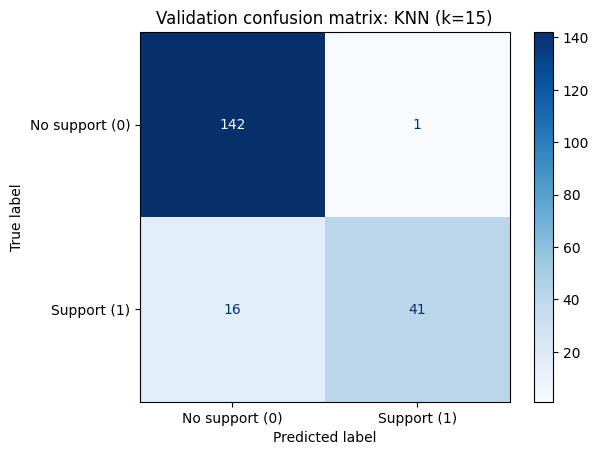

In [14]:
# Choose the model with the highest validation F1 score.
best_name = validation_results.index[0]
best_model = models[best_name]
valid_pred = best_model.predict(X_valid)

print("Selected using validation F1:", best_name)
print("Confusion matrix (actual rows, predicted columns):")
print(confusion_matrix(y_valid, valid_pred, labels=[0, 1]))

ConfusionMatrixDisplay.from_predictions(
    y_valid, valid_pred, labels=[0, 1],
    display_labels=["No support (0)", "Support (1)"],
    cmap="Blues"
)
plt.title(f"Validation confusion matrix: {best_name}")
plt.show()

**Think about it:** If the goal were to identify as many students needing support as possible, would recall or precision usually be the more relevant starting point? What trade-off might follow?

## 5. Cross-validation for a more stable comparison

A single validation split can give a result that depends on which observations happened to be held out. In **5-fold cross-validation**, the training data are divided into five folds. Each fold is used for validation once, while the remaining folds are used to fit the model.

We run cross-validation on the training portion only. The test set remains untouched.
Below you see a very detialed explanation of how the cross-validation and k-fold work.

In [15]:
# StratifiedKFold splits the data into `n_splits` folds while keeping the
# proportion of each class the same in every fold. This matters when classes
# are imbalanced, so each fold still "looks like" the full dataset.
# shuffle=True randomises the row order before splitting; random_state makes
# the split reproducible (same folds every time you run the notebook).

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_rows = []  # collect one summary row per model as a dict, then build a DataFrame
for name, model in models.items():
    # cross_validate fits the model once per fold and scores the held-out fold.
    # With 5 folds we get 5 scores per metric, one per fold.
    # cv=cv tells it to use our stratified 5-fold splitter;
    # scoring lists every metric to compute on each fold;
    # return_train_score=False means we only look at held-out (validation)
    # performance, not how well the model memorised its own training fold.
    scores = cross_validate(
        model, X_train, y_train, cv=cv,
        scoring=["accuracy", "precision", "recall", "f1"],
        return_train_score=False
    )
    # Average the 5 fold scores (mean) and measure their spread (std).
    # A low SD means performance is stable across folds; a high SD means the
    # result depends heavily on which rows happened to be held out.
    # Keys are prefixed "test_" because cross_validate names each fold's score
    # after the held-out part (the "test" fold of that split).
    cv_rows.append({
        "Model": name,
        "Accuracy mean": scores["test_accuracy"].mean(),
        "Accuracy SD": scores["test_accuracy"].std(),
        "Precision mean": scores["test_precision"].mean(),
        "Recall mean": scores["test_recall"].mean(),
        "F1 mean": scores["test_f1"].mean(),
        "F1 SD": scores["test_f1"].std()
    })

# Turn the list of dicts into a DataFrame, use the model name as the row index,
# and sort by mean F1 (best first) so the strongest model is at the top.
cv_results = pd.DataFrame(cv_rows).set_index("Model").sort_values("F1 mean", ascending=False)
cv_results.round(3)  # round to 3 decimal places for readability

,Accuracy mean,Accuracy SD,Precision mean,Recall mean,F1 mean,F1 SD
Model,,,,,,
KNN (k=15),0.875,0.024,0.891,0.646,0.744,0.062
Decision Tree,0.843,0.023,0.804,0.618,0.685,0.079
Logistic Regression,0.747,0.019,0.668,0.233,0.344,0.052


## 6. Data leakage: what not to do

Data leakage happens when information from validation/test data (or information unavailable at prediction time) influences model fitting. This can make evaluation look better than it really is. We discussed the potential danger of leakage in our earlier sessions in length. Now with the folds, you learn a bit more naunce regarding leakage.

**Incorrect approach:** fit a scaler on the entire dataset before splitting. The scaler then uses information about the distribution of the held-out data.

**Correct approach:** put preprocessing and the estimator in a `Pipeline`. During cross-validation, the scaler is fitted separately inside each training fold.

In [16]:
# Correct pattern: preprocessing is inside the pipeline.
safe_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

safe_scores = cross_validate(
    safe_model, X_train, y_train, cv=cv,
    scoring=["accuracy", "precision", "recall", "f1"]
)
print("Mean CV F1 with pipeline:", round(safe_scores["test_f1"].mean(), 3))

Mean CV F1 with pipeline: 0.344


## 7. Final evaluation: use the test set once

After selecting the approach using training/CV and validation results, refit the chosen model on the training plus validation data. Then evaluate it on the test set. Do not keep changing the model based on the test results; doing so turns the test set into another validation set.

Final selected model: KNN (k=15)


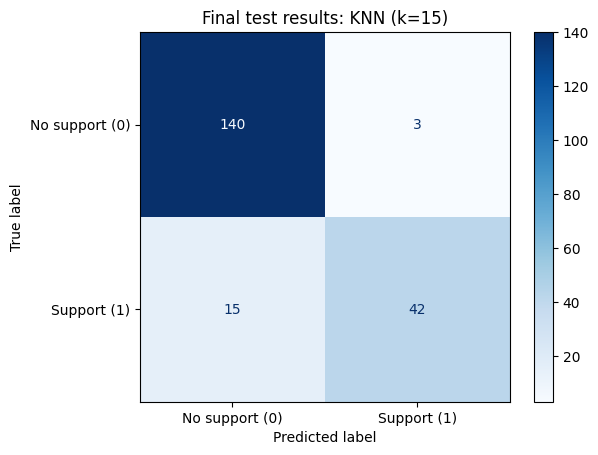

In [17]:
X_trainval = pd.concat([X_train, X_valid])
y_trainval = pd.concat([y_train, y_valid])

# Re-create the selected model with the same settings, then fit on train + validation.
final_models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ]),
    "KNN (k=15)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=15))
    ]),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE)
}
final_model = final_models[best_name]
final_model.fit(X_trainval, y_trainval)
test_pred = final_model.predict(X_test)

print("Final selected model:", best_name)
ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred,
    display_labels=["No support (0)", "Support (1)"],
    cmap="Blues"
)
plt.title(f"Final test results: {best_name}")
plt.show()

## 8. Questions to discuss
Q:
1. Why is training accuracy not a reliable estimate of performance on new data?
2. When could accuracy be misleading?
3. What is the difference between precision and recall?
4. Why should model selection not be based on the test set?
5. How does a pipeline help prevent data leakage?

A:
1. training accuracy is not reliable because the model could be overfitted to the training set.
2. a very biased dataset could have a very high accuracy while having a large Type 1 false alarm error.
3. precision is the amount of possitive predictions made by the model that were correct, while recall is the amount of true positives in the dataset that the model guessed correctly.
4. the test set acts as a way to check a models predictive ability without bias, selecting a model based off of the test set adds bias into the model through this selection.
5. by reliably seperating data and keeping it siloed.

### Key message

**Choose and tune using training data plus validation/cross-validation. Keep the test set for the final estimate. Choose metrics that match the problem.**